In [1]:
import pandas as pd
from pathlib import Path
from matplotlib.colors import PowerNorm
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

Path("images").mkdir(exist_ok=True)   # all figures are saved here

# Warmup

## Load Data

In [2]:
files = sorted(Path("Data").glob("*.csv"))

df = pd.concat(
    (pd.read_csv(
        f, 
        parse_dates=["started_at", "ended_at"], 
        dtype={"start_station_id": str, "end_station_id": str}
    ) for f in files),
    ignore_index=True,
)

df_raw_shape = df.shape
print(df_raw_shape)
df.head()

(5246236, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E4A8132DACF670C3,electric_bike,2026-08-10 14:31:22.100,2026-08-10 14:37:37.034,E 33 St & 5 Ave,6322.01,W 24 St & 7 Ave,6257.03,40.747659,-73.984907,40.744876,-73.995299,member
1,8382768C05C30BB4,electric_bike,2026-08-10 08:04:28.348,2026-08-10 08:33:27.680,Emerson Pl & Myrtle Ave,4683.02,W 24 St & 7 Ave,6257.03,40.693631,-73.962236,40.744876,-73.995299,member
2,3A1C43832BBE4FCD,classic_bike,2026-08-08 19:36:32.350,2026-08-08 19:43:47.890,Broadway & E 19 St,5980.11,W 24 St & 7 Ave,6257.03,40.738290,-73.990060,40.744876,-73.995299,member
3,5C9BC6DFC4DEA183,electric_bike,2026-08-05 14:34:27.749,2026-08-05 14:46:23.526,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member
4,355579CC64D1BE20,electric_bike,2026-08-01 14:16:44.531,2026-08-01 14:29:39.539,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member


## Cleaning

In [3]:
# Add a new column "ride_time" to the dataframe
df['ride_time'] = df['ended_at'] - df['started_at']

# Generate a boolean mask for each condition (too long, or negative)
long_ride_times = df["ride_time"] > pd.Timedelta(hours=3)
print("longer than 3 hours:", long_ride_times.sum())        # sum() counts all true values in the mask

negative_ride_times = df["ride_time"] < pd.Timedelta(0)
print("negative ride times:", negative_ride_times.sum())

missing_station = df["start_station_id"].isna() | df["end_station_id"].isna()
print("missing start/end station:", missing_station.sum())

df = df.loc[~(long_ride_times | negative_ride_times | missing_station)]
df_clean_shape = df.shape

print(f"before: {df_raw_shape}")
print(f"after: {df_clean_shape}")
print(f"dropped: {df_raw_shape[0] - df_clean_shape[0]} rows")

longer than 3 hours: 6020
negative ride times: 0
missing start/end station: 17156
before: (5246236, 13)
after: (5225284, 14)
dropped: 20952 rows


## 1) Histogram

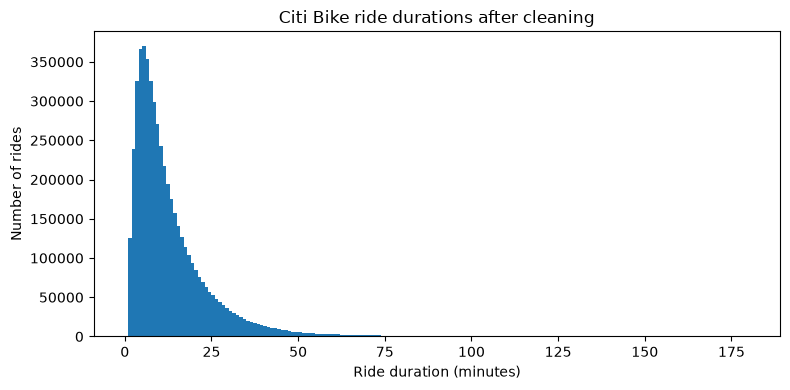

In [4]:
minutes = df["ride_time"].dt.total_seconds() / 60

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(minutes, bins=180, range=(0, 180))
ax.set_xlabel("Ride duration (minutes)")
ax.set_ylabel("Number of rides")
ax.set_title("Citi Bike ride durations after cleaning")
plt.tight_layout()
plt.savefig("images/ride_duration_histogram.png", dpi=200, bbox_inches="tight")
plt.show()

## 2) Expected time, and Variance

In [5]:
ride_times_in_minutes = df["ride_time"].dt.total_seconds() / 60

E_x = np.mean(ride_times_in_minutes)
Var_x = np.var(ride_times_in_minutes)
P_g20 = (ride_times_in_minutes > 20).sum() / df.shape[0]

print(f"E[X]: {E_x}")
print(f"Var[X]: {Var_x}")
print(f"P(X > 20): {P_g20}")

E[X]: 13.407342967224366
Var[X]: 157.21753576844358
P(X > 20): 0.18799016474511243


## 3) Conditional: P(X > 20 | Member)

In [6]:
# Citibike Members
citibike_member_rides = df["member_casual"] == "member"
P_member = citibike_member_rides.sum() / df.shape[0]

# Member, and ride longer than 20 minutes
citibike_member_and_g20_rides = (df["member_casual"] == "member") & ((df["ride_time"].dt.total_seconds() / 60) > 20)
P_g20_and_member = citibike_member_and_g20_rides.sum() / df.shape[0]

# P(X > 20 | Member)
P_g20_given_member = P_g20_and_member / P_member

print(f"P(X > 20 | Member): {P_g20_given_member}")

P(X > 20 | Member): 0.15331187684384096


## 4) P(member | X > 25)

In [7]:
p_joint = ((df["member_casual"] == "member") & ((df["ride_time"].dt.total_seconds() / 60) > 25)).sum()  # count(A and B)
p_ride_25_min = ((df["ride_time"].dt.total_seconds() / 60) > 25).sum()                                  # count(B)
print(f"P(member | ride > 25 min) = {p_joint / p_ride_25_min:.4f}")

P(member | ride > 25 min) = 0.6030


In [8]:
(df["member_casual"] == "member").mean()

np.float64(0.7859699109177607)

## 5) expected ride duration by bike type

In [9]:
electric_average_ride_time = df.loc[df["rideable_type"] == "electric_bike", "ride_time"].mean().total_seconds() / 60
classic_average_ride_time = df.loc[df["rideable_type"] == "classic_bike", "ride_time"].mean().total_seconds() / 60
print(f"Expected electric bike ride time: {electric_average_ride_time:.2f} min")
print(f"Expected classic bike ride time: {classic_average_ride_time:.2f} min")

Expected electric bike ride time: 13.36 min
Expected classic bike ride time: 13.54 min


## 6) P(bike type | X < 10)

In [10]:
short = df["ride_time"] < pd.Timedelta(minutes=10)
p_ride_less_than_10 = short.mean()                                      # P(B)

p_joint = ((df["rideable_type"] == "electric_bike") & short).mean()     # P(A and B)
print(f"P(Electric Bike | Ride < 10) = {p_joint / p_ride_less_than_10:.3f}")

p_joint = ((df["rideable_type"] == "classic_bike") & short).mean()
print(f"P(Classic Bike | Ride < 10) = {p_joint / p_ride_less_than_10:.3f}")

p_electric = (df["rideable_type"] == "electric_bike").mean()
print(f"P(Electric Bike) overall = {p_electric:.3f}")

P(Electric Bike | Ride < 10) = 0.720
P(Classic Bike | Ride < 10) = 0.280
P(Electric Bike) overall = 0.730


# Part I: Modeling Citi Bike stations using Markov chains

## Selected Variables

In [11]:
AM_HOURS = range(6, 11)         # 6:00–10:59
PM_HOURS = range(15, 20)        # 15:00–19:59
HOURS = list(AM_HOURS) + list(PM_HOURS)
stations = [
    "W 21 St & 6 Ave", 
    "11 Ave & W 41 St", 
    "S 2 St & Kent Ave"
    ]
station_capacities = [63, 48, 44]
WINDOWS_TO_TEST = [5, 10, 15, 20, 25, 30]
WINDOW = 10                     # number of minutes between windows

## Station Selection

In [12]:
def block_flows(df, hours):
    dep_mask = (df["started_at"].dt.dayofweek < 5) & df["started_at"].dt.hour.isin(hours)
    arr_mask = (df["ended_at"].dt.dayofweek < 5) & df["ended_at"].dt.hour.isin(hours)
    dep = df.loc[dep_mask].groupby("start_station_name").size()
    arr = df.loc[arr_mask].groupby("end_station_name").size()
    out = pd.DataFrame({"dep": dep, "arr": arr}).fillna(0)
    out["net"] = out["arr"] - out["dep"]
    out["total"] = out["arr"] + out["dep"]
    return out

am = block_flows(df, AM_HOURS)
pm = block_flows(df, PM_HOURS)

summary = am.add_suffix("_am").join(pm.add_suffix("_pm"), how="outer").fillna(0)
summary["total"] = summary["total_am"] + summary["total_pm"]
summary.sort_values("total", ascending=False).head(25)

,dep_am,arr_am,net_am,total_am,dep_pm,arr_pm,net_pm,total_pm,total
W 21 St & 6 Ave,2800.0,3948.0,1148.0,6748.0,5603.0,4589.0,-1014.0,10192.0,16940.0
9 Ave & W 33 St,2404.0,5117.0,2713.0,7521.0,5747.0,3300.0,-2447.0,9047.0,16568.0
Pier 61 at Chelsea Piers,2984.0,2905.0,-79.0,5889.0,5109.0,4838.0,-271.0,9947.0,15836.0
W 31 St & 7 Ave,2806.0,2847.0,41.0,5653.0,4432.0,4692.0,260.0,9124.0,14777.0
Park Ave & E 42 St,2733.0,3931.0,1198.0,6664.0,4246.0,3384.0,-862.0,7630.0,14294.0
E 17 St & Broadway,2128.0,3424.0,1296.0,5552.0,4662.0,3642.0,-1020.0,8304.0,13856.0
6 Ave & W 33 St,2286.0,2176.0,-110.0,4462.0,3949.0,4326.0,377.0,8275.0,12737.0
Broadway & W 25 St,1377.0,3189.0,1812.0,4566.0,4838.0,3174.0,-1664.0,8012.0,12578.0
1 Ave & E 68 St,2004.0,4009.0,2005.0,6013.0,4175.0,2135.0,-2040.0,6310.0,12323.0
Broadway & E 14 St,1905.0,2805.0,900.0,4710.0,4032.0,3413.0,-619.0,7445.0,12155.0


1. W 21 St & 6 Ave	  (Morning Surplus, Chelsea/Flatiron, 63 Docks)
2. 11 Ave & W 41 St     (Afternoon Surplus, Hell's Kitchen/Midtown West, 48 Docks)
3. S 2 St & Kent Ave	   (Brooklyn, Roughly Equal in/out, 44 Docks)

## Data Consolidation

In [13]:
print("Our stations:")
for station in stations:
    print(f"  {station}")
print(f"\nKeeping only rides that occur Mon-Fri, "
      f"{AM_HOURS.start}:00 - {AM_HOURS.stop - 1}:59 or {PM_HOURS.start}:00 - {PM_HOURS.stop - 1}:59")

# Remove all rides that fall outside our time windows
start_in_window = (df["started_at"].dt.dayofweek < 5) & df["started_at"].dt.hour.isin(HOURS)
end_in_window   = (df["ended_at"].dt.dayofweek < 5)   & df["ended_at"].dt.hour.isin(HOURS)
outside_window = ~(start_in_window | end_in_window)
print(f"removed {outside_window.sum()} rides outside weekday time windows")
df = df.loc[~outside_window]

# Remove all rides that do not start or end at one of our stations
at_our_stations = df["start_station_name"].isin(stations) | df["end_station_name"].isin(stations)
print(f"removed {(~at_our_stations).sum()} rides not starting or ending at our stations")
df = df.loc[at_our_stations]

# Print old vs new shape of df
df_filtered_shape = df.shape
print(f"before: {df_clean_shape}")
print(f"after: {df_filtered_shape}\n")



# Count and print number of arrivals and departures by each station
dep_mask = df["start_station_name"].isin(stations) & df["started_at"].dt.hour.isin(HOURS) & (df["started_at"].dt.dayofweek < 5)
arr_mask = df["end_station_name"].isin(stations) & df["ended_at"].dt.hour.isin(HOURS) & (df["ended_at"].dt.dayofweek < 5)
counts = pd.DataFrame({
    "departures": df.loc[dep_mask, "start_station_name"].value_counts(),
    "arrivals":   df.loc[arr_mask, "end_station_name"].value_counts(),
}).reindex(stations).fillna(0).astype(int)
counts["total"] = counts["departures"] + counts["arrivals"]

name_width = max(len(s) for s in stations)
for station, r in counts.iterrows():
    print(f"{station:<{name_width}} | arrivals: {r['arrivals']:>5} | departures: {r['departures']:>5} | total: {r['total']:>5}")

Our stations:
  W 21 St & 6 Ave
  11 Ave & W 41 St
  S 2 St & Kent Ave

Keeping only rides that occur Mon-Fri, 6:00 - 10:59 or 15:00 - 19:59
removed 3014905 rides outside weekday time windows
removed 2170481 rides not starting or ending at our stations
before: (5225284, 14)
after: (39898, 14)

W 21 St & 6 Ave   | arrivals:  8537 | departures:  8403 | total: 16940
11 Ave & W 41 St  | arrivals:  5559 | departures:  5913 | total: 11472
S 2 St & Kent Ave | arrivals:  5495 | departures:  5402 | total: 10897


## State Space, Time Step, etc Exploration

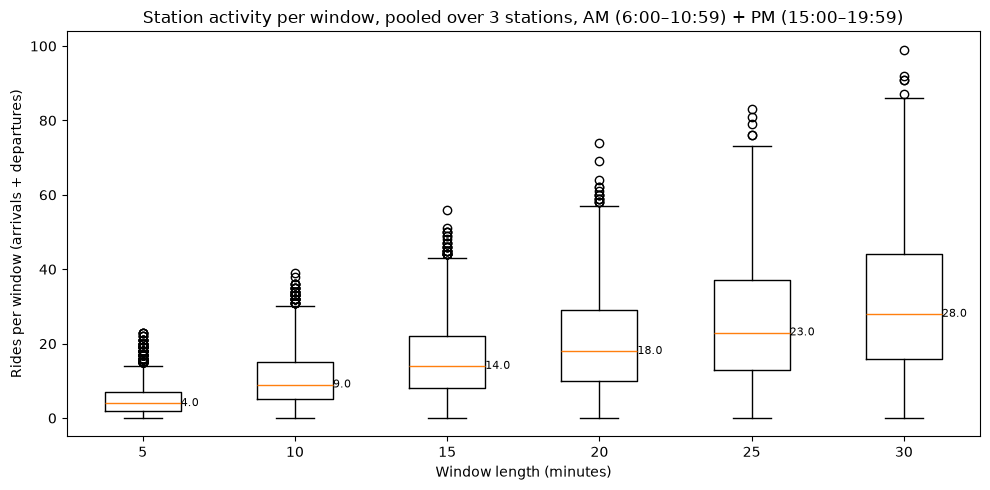

In [14]:
# Claude generated code. Box and whisker plot of the number of rides per window (arrivals + departures),
# pooled across all stations and both blocks, for each window length in WINDOWS_TO_TEST.

assert len(AM_HOURS) == len(PM_HOURS), "AM and PM blocks must be the same length"
BLOCK_LEN = len(AM_HOURS) * 60     # minutes per block

# Uses dep_mask / arr_mask from the arrivals/departures count cell above
dep = df.loc[dep_mask, ["start_station_name", "started_at"]].set_axis(["station", "time"], axis=1)
arr = df.loc[arr_mask, ["end_station_name", "ended_at"]].set_axis(["station", "time"], axis=1)
events = pd.concat([dep, arr], ignore_index=True)

# Which day and block each event is in, and how many minutes into the block it happened
events["date"] = events["time"].dt.normalize()
events["block"] = np.where(events["time"].dt.hour.isin(AM_HOURS), "AM", "PM")
block_start_min = np.where(events["block"] == "AM", AM_HOURS.start, PM_HOURS.start) * 60
events["offset"] = events["time"].dt.hour * 60 + events["time"].dt.minute - block_start_min

days = sorted(events["date"].unique())
box_data = []

for L in WINDOWS_TO_TEST:
    n_windows = -(-BLOCK_LEN // L)          # round up so a partial window is included
    counts = (events.assign(window=events["offset"] // L)
                    .groupby(["station", "date", "block", "window"]).size())

    # Fill in windows with no events as 0
    full_grid = pd.MultiIndex.from_product(
        [stations, days, ["AM", "PM"], range(n_windows)], names=counts.index.names)
    counts = counts.reindex(full_grid, fill_value=0).astype(float)

    # Scale up a partial last window (e.g. 20 of 40 min → ×2)
    leftover = BLOCK_LEN % L
    if leftover:
        last = counts.index.get_level_values("window") == n_windows - 1
        counts.loc[last] *= L / leftover

    box_data.append(counts.values)

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(box_data)
for i, d in enumerate(box_data, start=1):
    med = np.median(d)
    ax.text(i + 0.25, med, f"{med:.1f}", va="center", fontsize=8)
ax.set_xticks(range(1, len(WINDOWS_TO_TEST) + 1), [str(L) for L in WINDOWS_TO_TEST])
ax.set_xlabel("Window length (minutes)")
ax.set_ylabel("Rides per window (arrivals + departures)")
ax.set_title(f"Station activity per window, pooled over {len(stations)} stations, "
             f"AM ({AM_HOURS.start}:00–{AM_HOURS.stop - 1}:59) + PM ({PM_HOURS.start}:00–{PM_HOURS.stop - 1}:59)")
plt.tight_layout()
plt.savefig("images/window_length_exploration_box_plots.png", dpi=200, bbox_inches="tight")
plt.show()

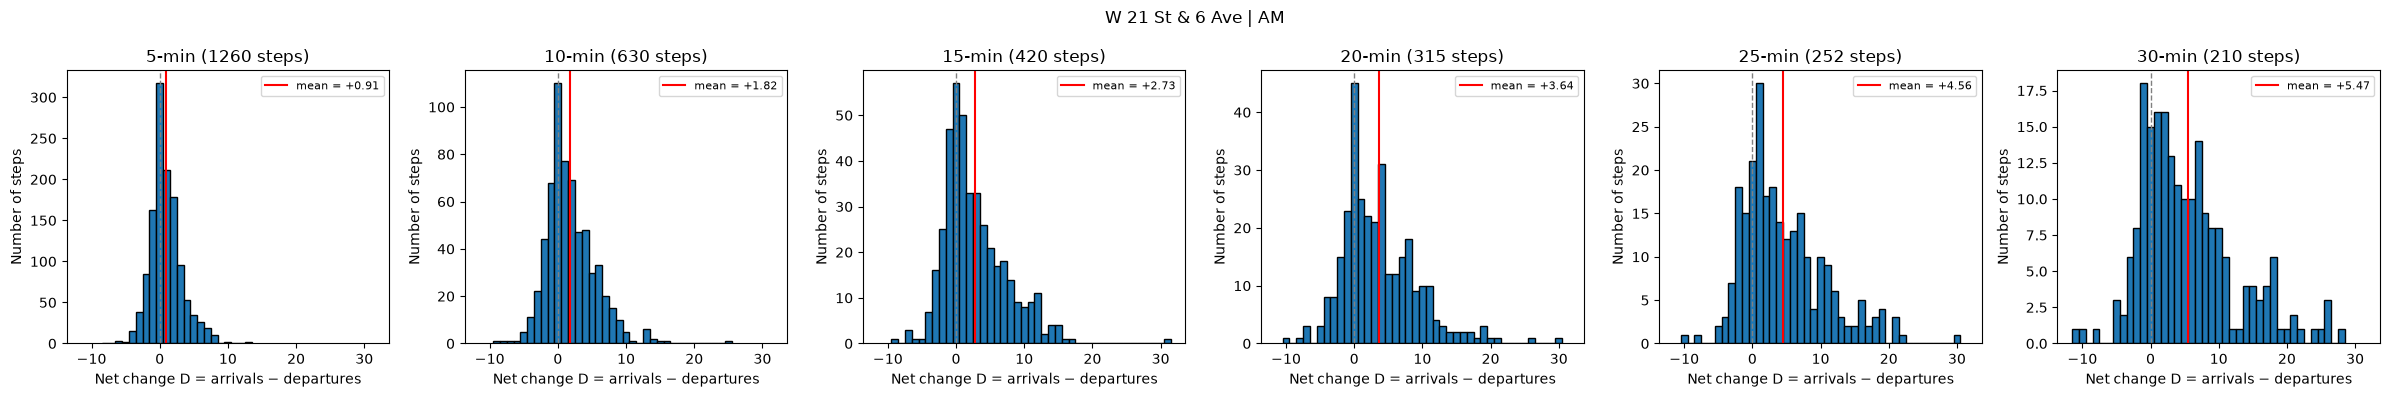

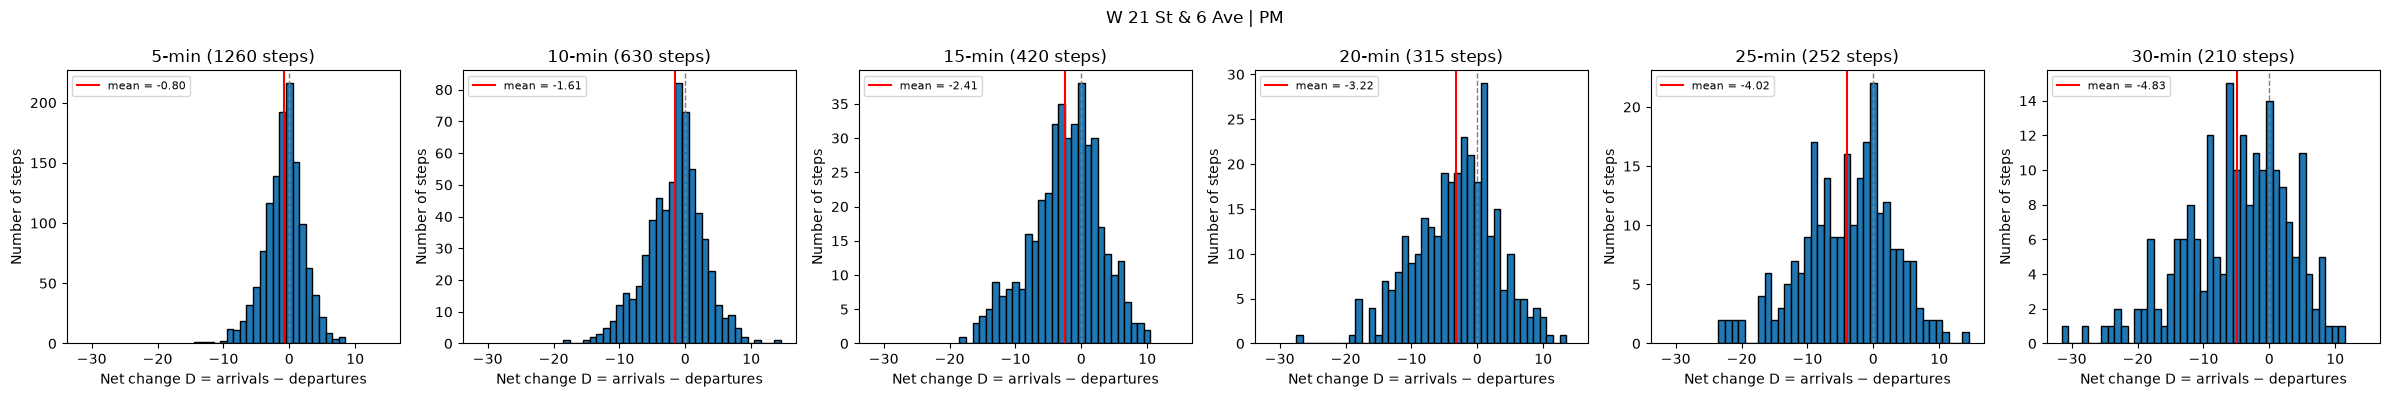

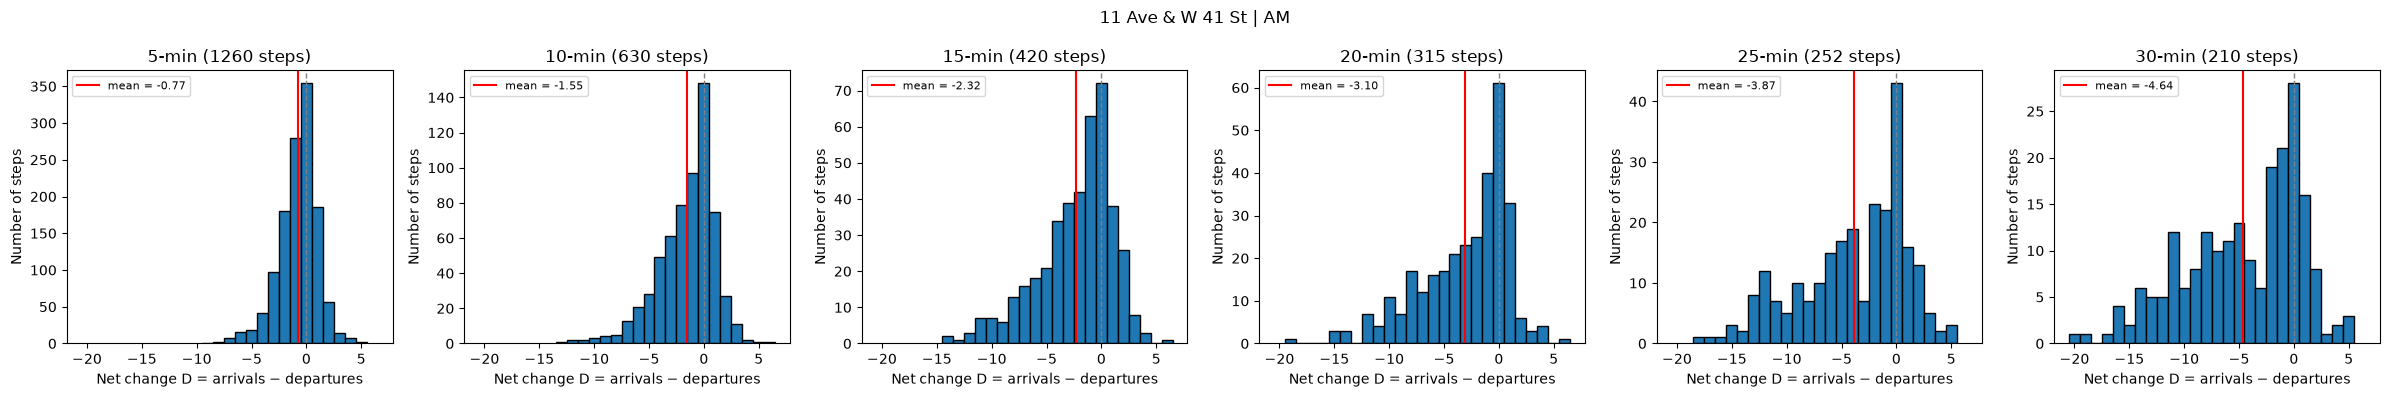

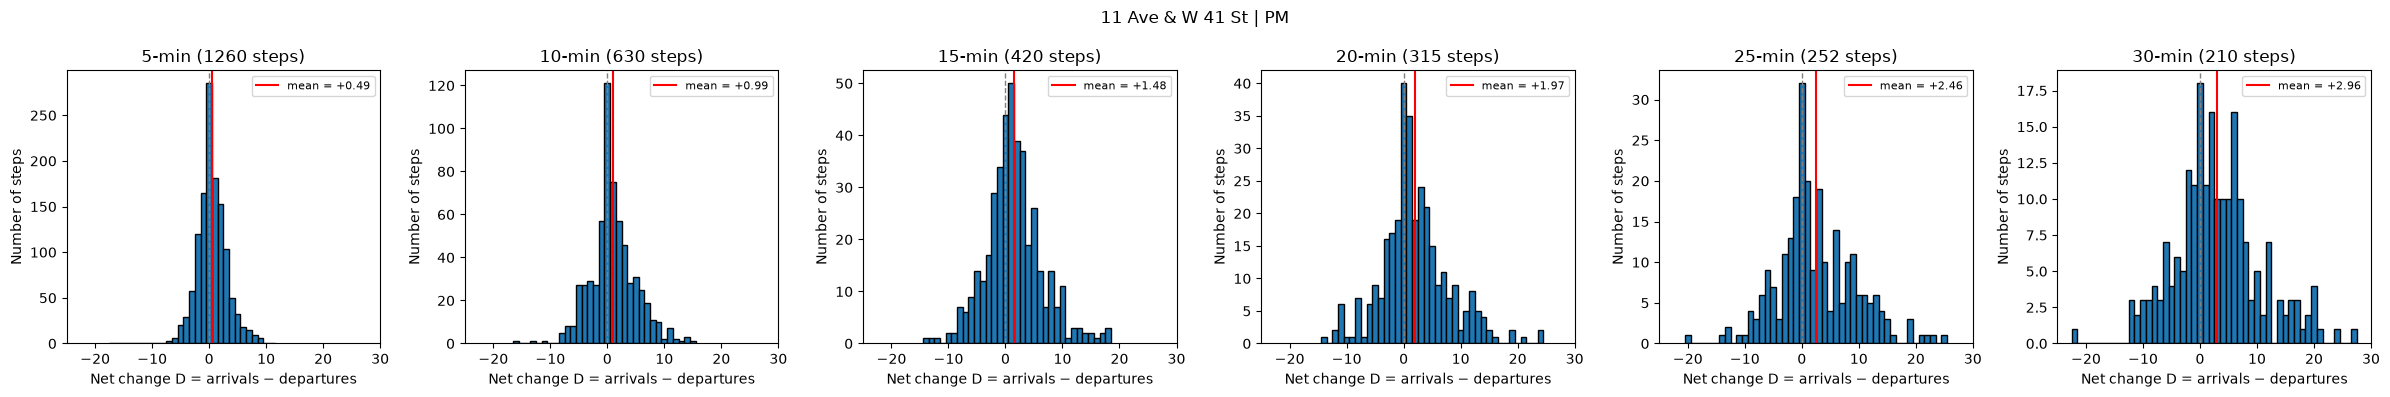

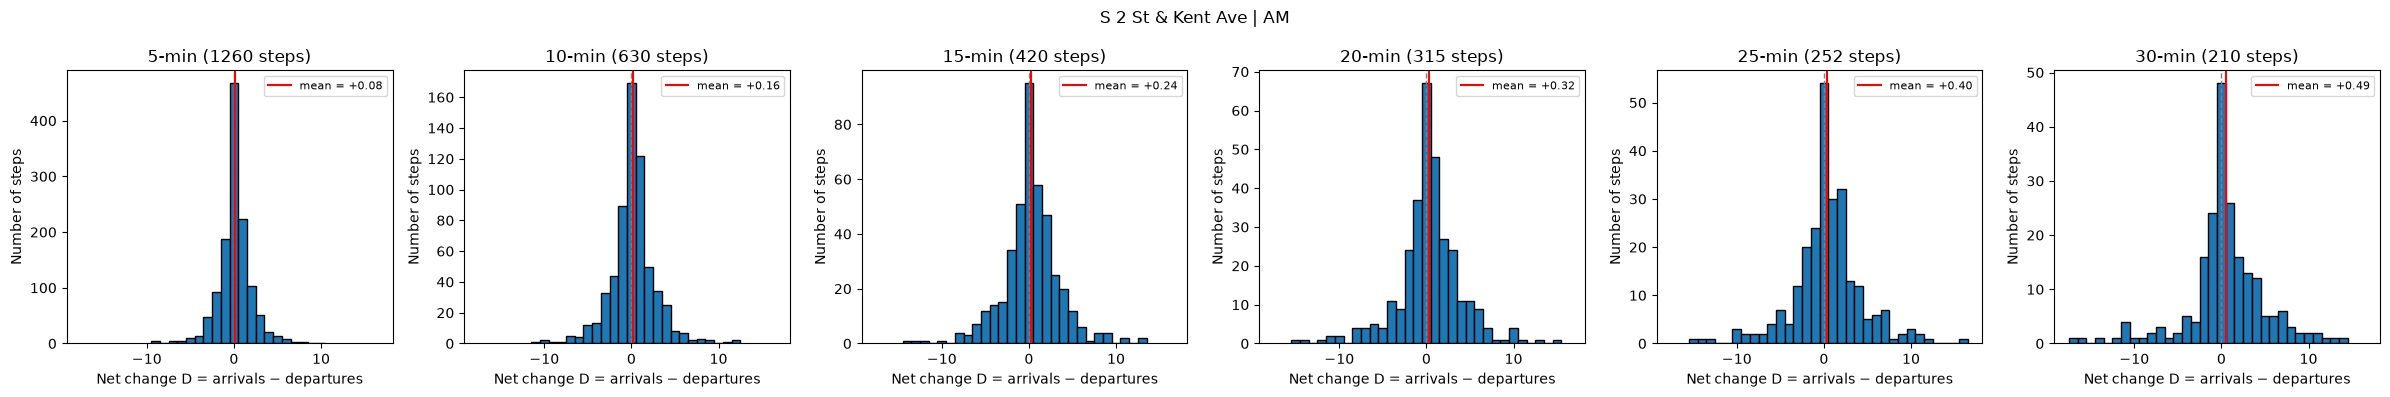

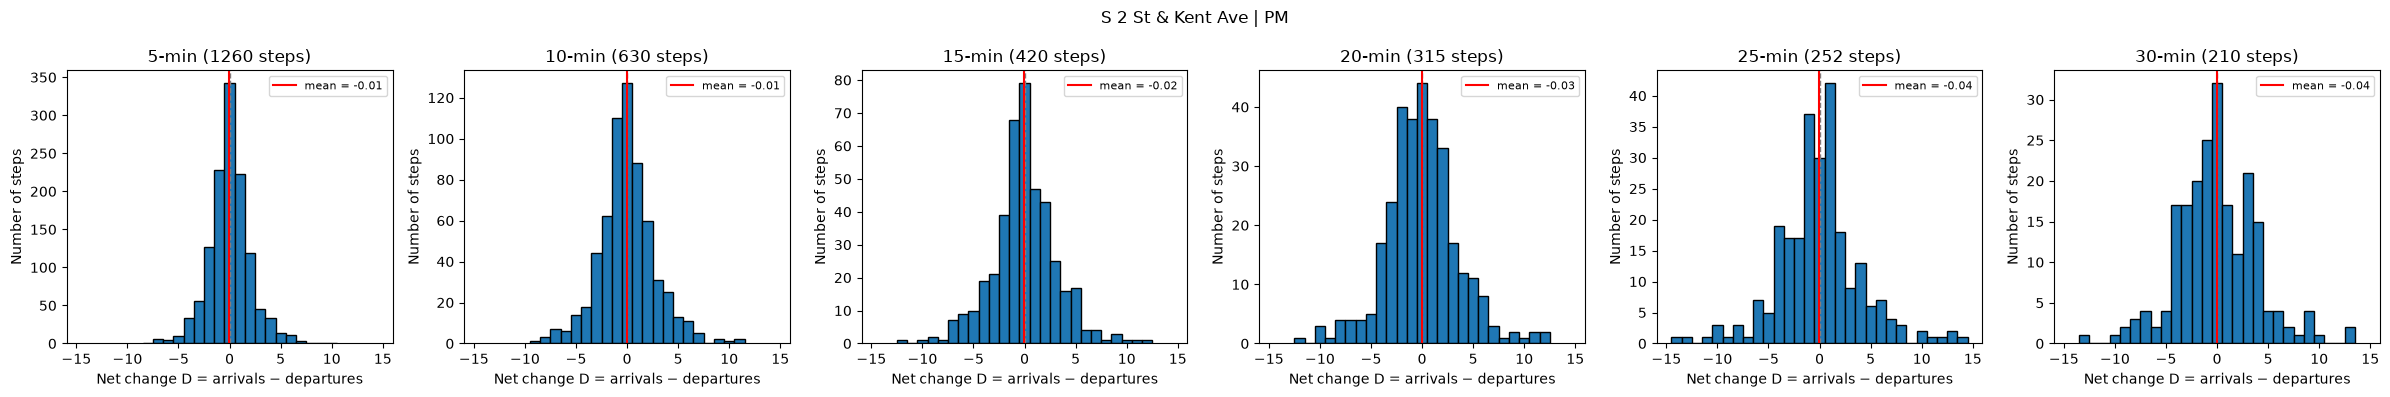

In [15]:
# ---------------------------------------------------------------------------
# Net-flow data. Determine net bike incoming/outgoing flow for each window
# ---------------------------------------------------------------------------
AUG_WEEKDAYS = pd.date_range("2026-08-01", "2026-08-31", freq="B")   # Mon–Fri, 21 days
def step_counts(times, hours, window, days=AUG_WEEKDAYS):
    """Number of events in each `window`-minute step of a block, for every day, in time order.
    Steps with no events are 0. Length = len(days) * (block minutes / window)."""
    block_len = len(hours) * 60
    assert block_len % window == 0, f"window ({window}) must divide the block length ({block_len} min)"
    n_steps = block_len // window

    minutes_in = (times - times.dt.normalize()).dt.total_seconds() / 60 - hours.start * 60
    in_block = (minutes_in >= 0) & (minutes_in < block_len)

    step = (minutes_in[in_block] // window).astype(int)
    date = times[in_block].dt.normalize()
    counts = step.groupby([date, step]).size()

    # Full grid of (day, step), so empty steps count as 0 and weekends drop out
    grid = pd.MultiIndex.from_product([days, range(n_steps)])
    return counts.reindex(grid, fill_value=0).to_numpy()


def net_flow_arrays(df, station, am_hours, pm_hours, window, days=AUG_WEEKDAYS):
    """Return (am_D, pm_D): arrivals - departures at `station` for every step in each block."""
    dep_times = df.loc[df["start_station_name"] == station, "started_at"]
    arr_times = df.loc[df["end_station_name"] == station, "ended_at"]
    am_D = step_counts(arr_times, am_hours, window, days) - step_counts(dep_times, am_hours, window, days)
    pm_D = step_counts(arr_times, pm_hours, window, days) - step_counts(dep_times, pm_hours, window, days)
    return am_D, pm_D


# ---------------------------------------------------------------------------
# Plotting
# ---------------------------------------------------------------------------

def slugify(name):
    """'W 21 St & 6 Ave' -> 'w_21_st_6_ave' (safe for file names)."""
    return "_".join("".join(c if c.isalnum() else " " for c in name.lower()).split())


def plot_D_hist(D, title="", ax=None):
    """Histogram of a net-change array D, one bar per integer value."""
    D = np.asarray(D)
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))

    bins = np.arange(D.min() - 0.5, D.max() + 1.5, 1)   # one bin per integer, centered on it
    ax.hist(D, bins=bins, edgecolor="black")
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.axvline(D.mean(), color="red", linewidth=1.5, label=f"mean = {D.mean():+.2f}")
    ax.set_title(title)
    ax.set_xlabel("Net change D = arrivals − departures")
    ax.set_ylabel("Number of steps")
    ax.legend(fontsize=8)
    return ax


def plot_D_hist_row(arrays, labels, title="", panel_width=4, save_path=None):
    """Side-by-side D histograms, one panel per array (e.g. one per window length)."""
    fig, axes = plt.subplots(1, len(arrays), figsize=(panel_width * len(arrays), 4), sharex=True)
    for ax, D, label in zip(np.atleast_1d(axes), arrays, labels):
        plot_D_hist(D, title=label, ax=ax)
    fig.suptitle(title)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


def plot_window_comparison(df, station, windows, am_hours, pm_hours):
    """For one station, plot D histograms across window lengths: one row for AM, one for PM."""
    results = {w: net_flow_arrays(df, station, am_hours, pm_hours, w) for w in windows}   # w -> (am_D, pm_D)
    for b, block in enumerate(["AM", "PM"]):
        plot_D_hist_row([results[w][b] for w in windows],
                        [f"{w}-min ({len(results[w][b])} steps)" for w in windows],
                        title=f"{station} | {block}",
                        save_path=f"images/net_flow_{slugify(station)}_{block.lower()}.png")

# D histograms across all test window lengths, for each station
for station in stations:
    plot_window_comparison(df, station, WINDOWS_TO_TEST, AM_HOURS, PM_HOURS)

## Building Markov Chains

In [16]:
# ---------------------------------------------------------------------------
# Transition matrices
# ---------------------------------------------------------------------------

def build_transition_matrix(D, capacity):
    """
    (capacity+1) x (capacity+1) transition matrix from an array of net changes D.
    P[i, j] = P(next state = j | current state = i) = P(D = j - i),
    with any move below 0 or above capacity counted as a move to 0 or capacity.
    """
    D = np.asarray(D)
    values, counts = np.unique(D, return_counts=True)
    probs = counts / counts.sum()                       # empirical P(D = d)

    P = np.zeros((capacity + 1, capacity + 1))
    for i in range(capacity + 1):
        next_states = np.clip(i + values, 0, capacity)  # impossible states → 0 or capacity
        np.add.at(P[i], next_states, probs)             # add, since several d values can land on the same j

    assert np.allclose(P.sum(axis=1), 1), "every row should sum to 1"
    return P


def build_station_matrices(am_D, pm_D, capacity):
    """Return a dict with the AM, PM, and combined transition matrices for one station."""
    return {
        "AM": build_transition_matrix(am_D, capacity),
        "PM": build_transition_matrix(pm_D, capacity),
        "Combined": build_transition_matrix(np.concatenate([am_D, pm_D]), capacity),
    }


def build_all_matrices(df, stations, capacities, am_hours, pm_hours, window):
    """
    Build the AM / PM / Combined transition matrices for every station.
    Returns (MCs, Ds):
      MCs[station][block] -> transition matrix
      Ds[station][block]  -> the net-change array it was built from
    """
    assert len(stations) == len(capacities), "need one capacity per station"
    MCs, Ds = {}, {}
    for station, capacity in zip(stations, capacities):
        am_D, pm_D = net_flow_arrays(df, station, am_hours, pm_hours, window)
        Ds[station] = {"AM": am_D, "PM": pm_D, "Combined": np.concatenate([am_D, pm_D])}
        MCs[station] = build_station_matrices(am_D, pm_D, capacity)
    return MCs, Ds

In [17]:
MCs, Ds = build_all_matrices(df, stations, station_capacities, AM_HOURS, PM_HOURS, WINDOW)

name_width = max(len(s) for s in stations)
for station, capacity in zip(stations, station_capacities):
    print(f"{station:<{name_width}} | capacity {capacity} | "
          f"steps AM {len(Ds[station]['AM'])}, PM {len(Ds[station]['PM'])} | "
          f"mean D AM {Ds[station]['AM'].mean():+.2f}, PM {Ds[station]['PM'].mean():+.2f} | "
          f"matrix shape {MCs[station]['AM'].shape}")

W 21 St & 6 Ave   | capacity 63 | steps AM 630, PM 630 | mean D AM +1.82, PM -1.61 | matrix shape (64, 64)
11 Ave & W 41 St  | capacity 48 | steps AM 630, PM 630 | mean D AM -1.55, PM +0.99 | matrix shape (49, 49)
S 2 St & Kent Ave | capacity 44 | steps AM 630, PM 630 | mean D AM +0.16, PM -0.01 | matrix shape (45, 45)


In [18]:
# Summary of D for each station and block (Part I Q2 table)
steps_per_block = len(AM_HOURS) * 60 // WINDOW
D_summary = pd.DataFrame([
    {"station": s, "block": b, "mean D": Ds[s][b].mean(), "std D": Ds[s][b].std(),
     "drift per block": Ds[s][b].mean() * steps_per_block}
    for s in stations for b in ["AM", "PM"]
])
print(D_summary.round(2).to_string(index=False))

          station block  mean D  std D  drift per block
  W 21 St & 6 Ave    AM    1.82   3.62            54.67
  W 21 St & 6 Ave    PM   -1.61   4.32           -48.29
 11 Ave & W 41 St    AM   -1.55   2.63           -46.43
 11 Ave & W 41 St    PM    0.99   4.00            29.57
S 2 St & Kent Ave    AM    0.16   2.60             4.86
S 2 St & Kent Ave    PM   -0.01   2.73            -0.43


In [19]:
# ---------------------------------------------------------------------------
# Lag-1 autocorrelation of D (checks the independence assumption)
# ---------------------------------------------------------------------------

N_DAYS = len(AUG_WEEKDAYS)  # 21 weekdays in August 2026

def lag1_autocorr(D, n_days=N_DAYS):
    """
    Correlation between D_t and D_{t+1}, pairing only consecutive steps
    within the same day (assumes D is ordered day by day, then by time).
    """
    D = np.asarray(D)
    assert len(D) % n_days == 0, "D length should be a multiple of the number of days"
    D = D.reshape(n_days, -1)          # one row per day, one column per step
    x = D[:, :-1].ravel()              # D_t
    y = D[:, 1:].ravel()               # D_{t+1}
    return np.corrcoef(x, y)[0, 1]

for station in stations:
    for block in ["AM", "PM"]:
        print(f"{station:<{name_width}} | {block} | "
              f"lag-1 autocorr {lag1_autocorr(Ds[station][block]):+.3f}")

W 21 St & 6 Ave   | AM | lag-1 autocorr +0.201
W 21 St & 6 Ave   | PM | lag-1 autocorr +0.034
11 Ave & W 41 St  | AM | lag-1 autocorr +0.237
11 Ave & W 41 St  | PM | lag-1 autocorr +0.092
S 2 St & Kent Ave | AM | lag-1 autocorr +0.075
S 2 St & Kent Ave | PM | lag-1 autocorr -0.122


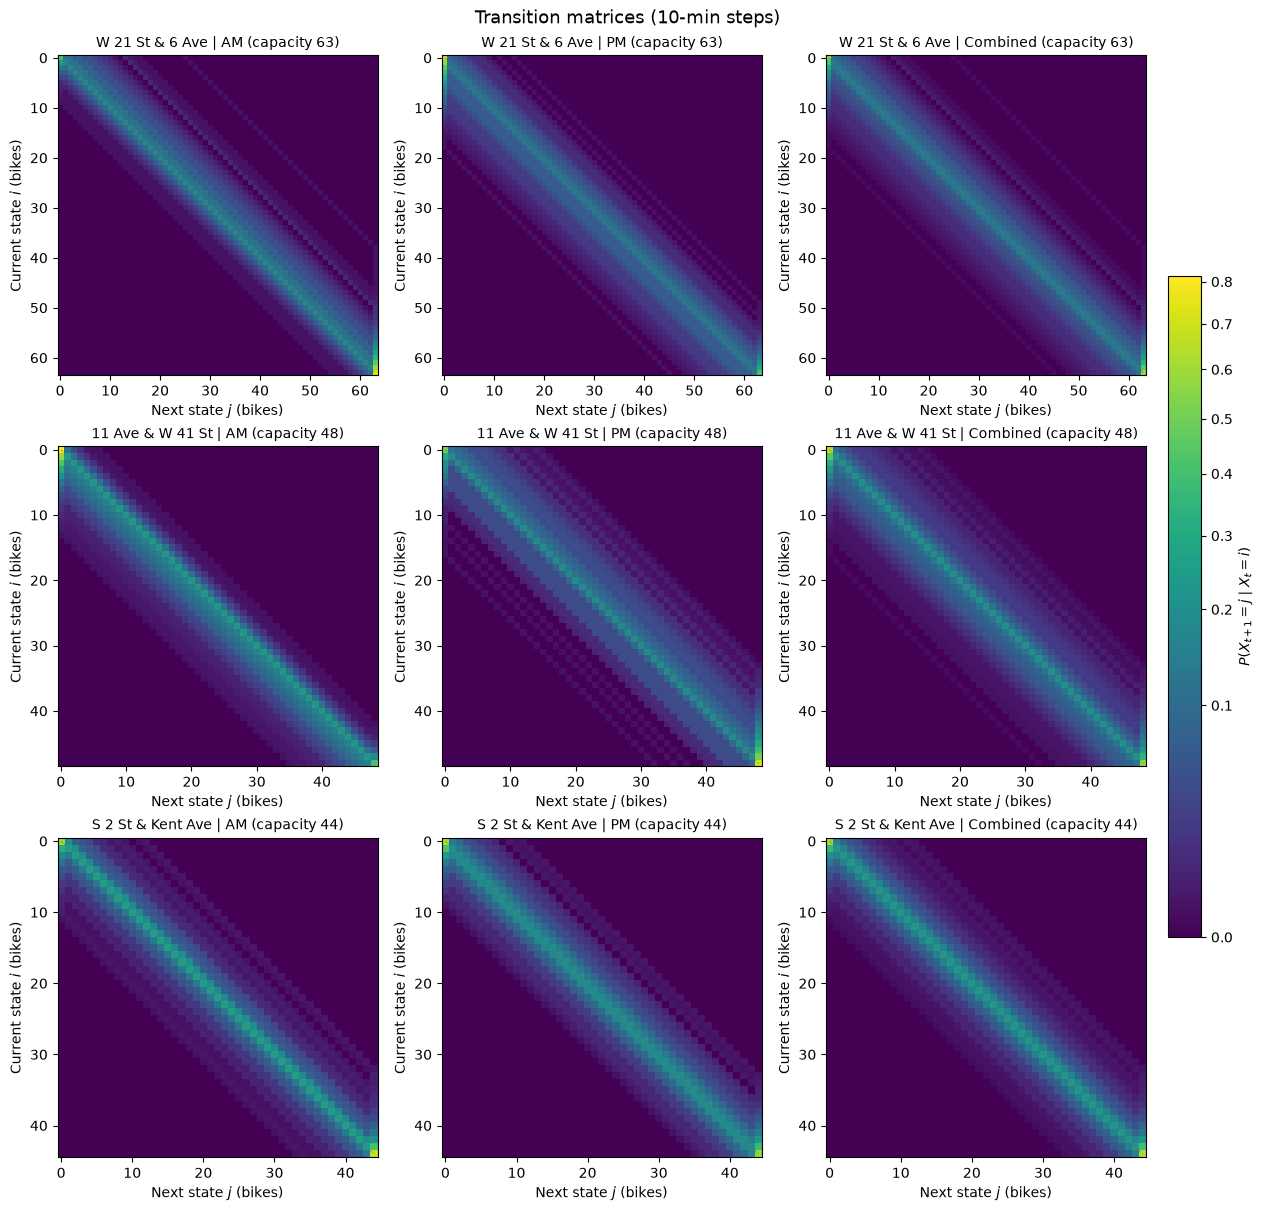

In [20]:
def plot_transition_heatmap(P, ax, title="", norm=None, cmap="viridis"):
    """Heatmap of one transition matrix: rows = current state i, cols = next state j."""
    capacity = P.shape[0] - 1
    im = ax.imshow(P, cmap=cmap, norm=norm, origin="upper", interpolation="nearest",
                   extent=(-0.5, capacity + 0.5, capacity + 0.5, -0.5))
    ax.plot([0, capacity], [0, capacity], color="0.4", lw=0.6, ls="--", alpha=0.6)  # diagonal = "no change"
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Next state $j$ (bikes)")
    ax.set_ylabel("Current state $i$ (bikes)")
    ax.set_xticks(range(0, capacity + 1, 10))
    ax.set_yticks(range(0, capacity + 1, 10))
    return im


def plot_all_transition_heatmaps(MCs, stations, blocks=("AM", "PM", "Combined"),
                                 gamma=0.5, save_path=None):
    """
    Grid of heatmaps: one row per station, one column per time block.
    All panels share one color scale. PowerNorm with gamma < 1 brightens the
    small off-diagonal probabilities so the spread of D is visible.
    """
    vmax = max(MCs[s][b].max() for s in stations for b in blocks)
    norm = PowerNorm(gamma=gamma, vmin=0, vmax=vmax)

    fig, axes = plt.subplots(len(stations), len(blocks),
                             figsize=(4.2 * len(blocks), 4 * len(stations)),
                             constrained_layout=True)
    axes = np.atleast_2d(axes)
    for r, station in enumerate(stations):
        cap = MCs[station][blocks[0]].shape[0] - 1
        for c, block in enumerate(blocks):
            im = plot_transition_heatmap(MCs[station][block], axes[r, c],
                                         title=f"{station} | {block} (capacity {cap})", norm=norm)
    cbar = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
    cbar.set_label(r"$P(X_{t+1} = j \mid X_t = i)$")
    fig.suptitle(f"Transition matrices ({WINDOW}-min steps)", fontsize=13)
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


plot_all_transition_heatmaps(MCs, stations, save_path="images/transition_matrix_heatmaps.png")

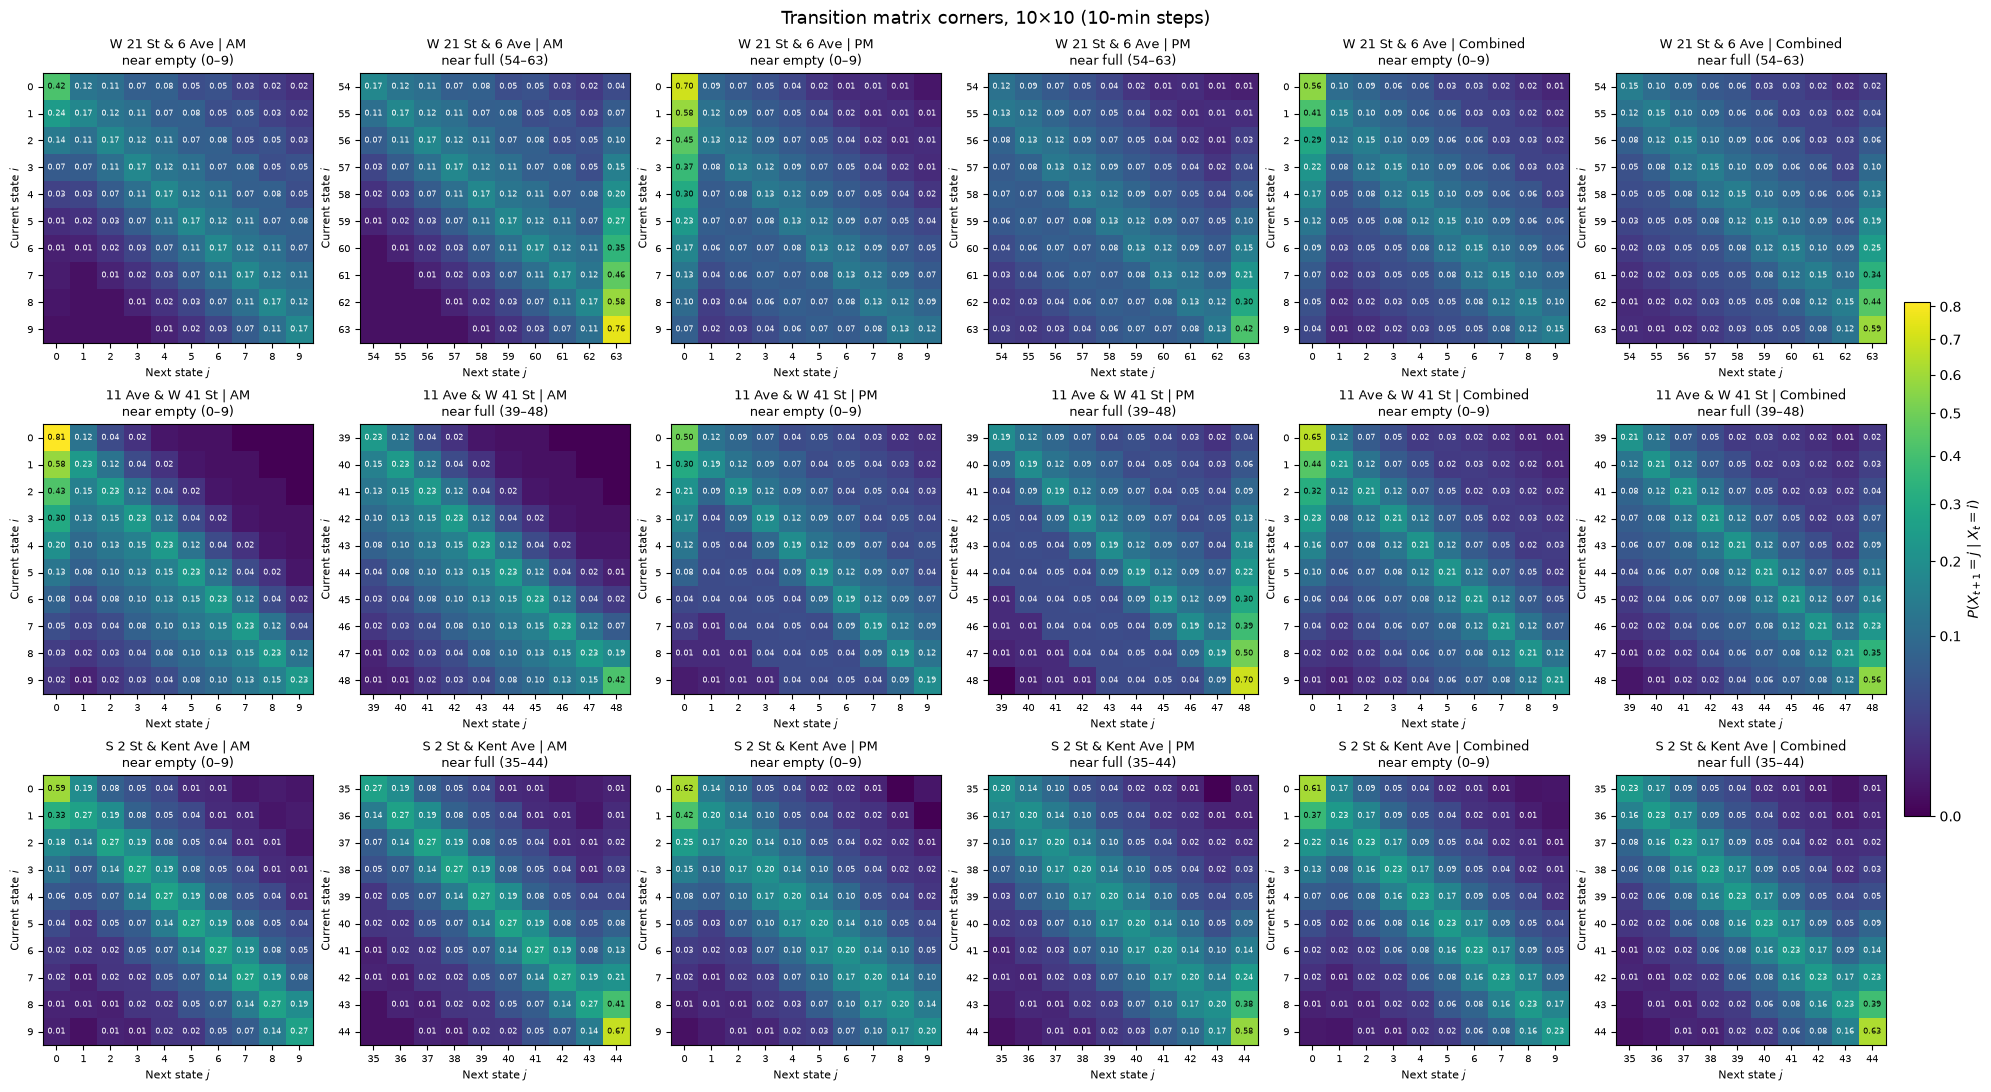

In [21]:
def plot_corner_heatmap(P, ax, corner, k=10, title="", norm=None, cmap="viridis", annotate=True):
    """
    Zoomed heatmap of one k x k corner of a transition matrix.
    corner="empty" -> states 0..k-1 (top-left); corner="full" -> last k states (bottom-right).
    Cells are labelled with their probability (blank if < 0.005).
    """
    n = P.shape[0]
    k = min(k, n)
    lo = 0 if corner == "empty" else n - k
    sub = P[lo:lo + k, lo:lo + k]
    states = np.arange(lo, lo + k)

    im = ax.imshow(sub, cmap=cmap, norm=norm, origin="upper", interpolation="nearest")
    ax.set_xticks(range(k), states, fontsize=7)
    ax.set_yticks(range(k), states, fontsize=7)
    ax.set_xlabel("Next state $j$", fontsize=8)
    ax.set_ylabel("Current state $i$", fontsize=8)
    ax.set_title(title, fontsize=9)

    if annotate:
        cmap_obj = plt.get_cmap(cmap)
        for r in range(k):
            for c in range(k):
                p = sub[r, c]
                if p < 0.005:
                    continue
                shade = norm(p) if norm is not None else p / sub.max()
                text_color = "black" if shade > 0.6 else "white"     # dark text on the yellow end
                ax.text(c, r, f"{p:.2f}", ha="center", va="center", fontsize=5.5, color=text_color)
    return im


def plot_all_corner_heatmaps(MCs, stations, blocks=("AM", "PM", "Combined"), k=10,
                             gamma=0.5, cmap="viridis", save_path=None):
    """
    One row per station; for each block, two panels side by side:
    the near-empty corner (top-left) and the near-full corner (bottom-right).
    Uses the same color scale as the full heatmaps so the two figures are comparable.
    """
    vmax = max(MCs[s][b].max() for s in stations for b in blocks)
    norm = PowerNorm(gamma=gamma, vmin=0, vmax=vmax)

    ncols = 2 * len(blocks)
    fig, axes = plt.subplots(len(stations), ncols,
                             figsize=(3.3 * ncols, 3.6 * len(stations)),
                             constrained_layout=True)
    axes = np.atleast_2d(axes)
    for r, station in enumerate(stations):
        cap = MCs[station][blocks[0]].shape[0] - 1
        for b, block in enumerate(blocks):
            P = MCs[station][block]
            plot_corner_heatmap(P, axes[r, 2 * b], "empty", k=k, norm=norm, cmap=cmap,
                                title=f"{station} | {block}\nnear empty (0–{k - 1})")
            im = plot_corner_heatmap(P, axes[r, 2 * b + 1], "full", k=k, norm=norm, cmap=cmap,
                                     title=f"{station} | {block}\nnear full ({cap - k + 1}–{cap})")
    cbar = fig.colorbar(im, ax=axes, shrink=0.5, pad=0.01)
    cbar.set_label(r"$P(X_{t+1} = j \mid X_t = i)$")
    fig.suptitle(f"Transition matrix corners, {k}×{k} ({WINDOW}-min steps)", fontsize=13)
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


plot_all_corner_heatmaps(MCs, stations, k=10, save_path="images/transition_matrix_corners.png")

## Computing Stationary Distributions

In [22]:

def is_irreducible(P, tol=1e-12):
    """Function returns True if input matrix is irreducible, returns false if not"""
    # Convert positive transition probabilities into a directed adjacency matrix
    adj_matrix = csr_matrix(P > tol)
    
    # Find the number of strongly connected components
    n_components = connected_components(
        csgraph=adj_matrix, 
        directed=True, 
        connection='strong', 
        return_labels=False
    )
    
    return n_components == 1

for station, blocks in MCs.items():
    for block, P in blocks.items():
        print(f"{station} | {block}: irreducible? {is_irreducible(P)}")

W 21 St & 6 Ave | AM: irreducible? True
W 21 St & 6 Ave | PM: irreducible? True
W 21 St & 6 Ave | Combined: irreducible? True
11 Ave & W 41 St | AM: irreducible? True
11 Ave & W 41 St | PM: irreducible? True
11 Ave & W 41 St | Combined: irreducible? True
S 2 St & Kent Ave | AM: irreducible? True
S 2 St & Kent Ave | PM: irreducible? True
S 2 St & Kent Ave | Combined: irreducible? True


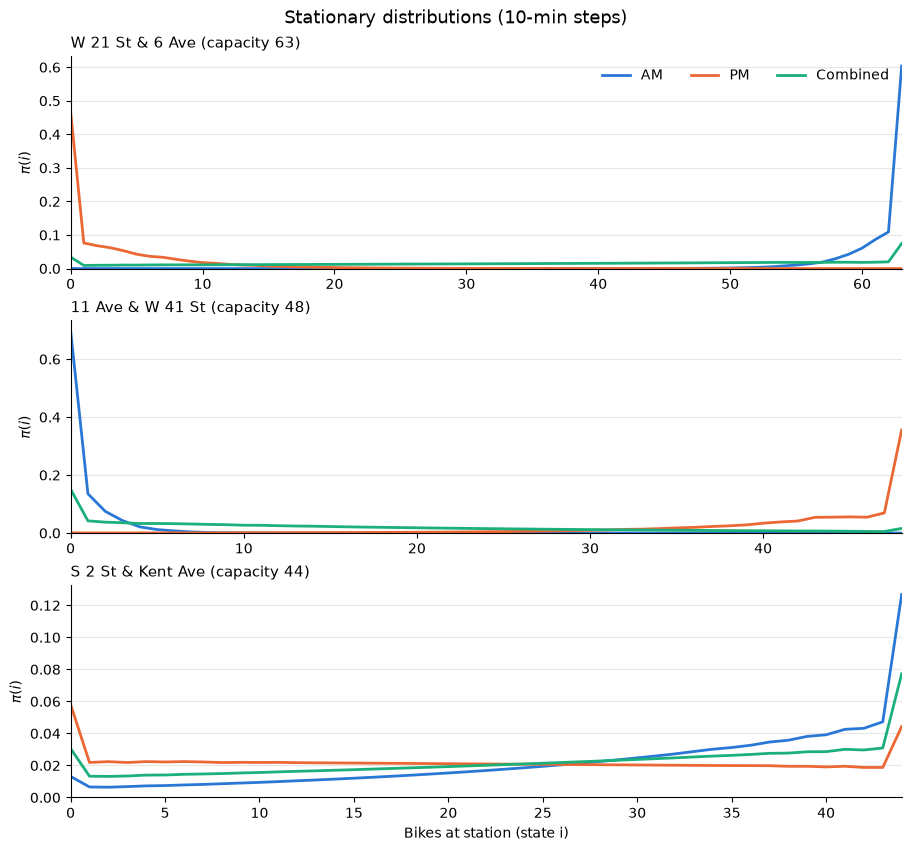

In [23]:
# computing stationary distributions
def compute_stationary_distributions(MCs):
    """Returns pis[station][block] -> stationary distribution of that transition matrix."""
    pis = {}
    for station, blocks in MCs.items():
        for block, P in blocks.items():
            n = len(P)
            # Stationary distribution: solve pi P = pi with sum(pi) = 1
            # Rewrite as (P^T - I) pi = 0, then replace the last (redundant)
            # equation with the normalization condition.
            A = np.vstack([(P.T - np.eye(n))[:-1], np.ones(n)])
            b = np.zeros(n); b[-1] = 1
            pi = np.linalg.solve(A, b)
            assert np.allclose(pi @ P, pi) and np.isclose(pi.sum(), 1), f"bad pi for {station} {block}"
            pis.setdefault(station, {})[block] = pi
    return pis

# visualizing distributions
SERIES_COLORS = {"AM": "#2a78d6", "PM": "#eb6834", "Combined": "#1baf7a"}

def plot_stationary_distributions(pis, stations, blocks=("AM", "PM", "Combined"), save_path=None):
    fig, axes = plt.subplots(len(stations), 1, figsize=(9, 2.8 * len(stations)),
                             constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, station in zip(axes, stations):
        for block in blocks:
            pi = pis[station][block]
            ax.plot(np.arange(len(pi)), pi, lw=2, color=SERIES_COLORS[block], label=block)
        cap = len(pis[station][blocks[0]]) - 1
        ax.set_xlim(0, cap)
        ax.set_ylim(bottom=0)
        ax.set_title(f"{station} (capacity {cap})", loc="left", fontsize=11)
        ax.set_ylabel(r"$\pi(i)$")
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[-1].set_xlabel("Bikes at station (state i)")
    axes[0].legend(frameon=False, ncol=len(blocks), loc="upper right")
    fig.suptitle(f"Stationary distributions ({WINDOW}-min steps)", fontsize=13)
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

pis = compute_stationary_distributions(MCs)
plot_stationary_distributions(pis, stations, save_path="images/stationary_distributions.png")



In [24]:
# Long-run probability of being empty / full
stationary_summary = pd.DataFrame([
    {"station": s, "block": b, "P(empty)": pis[s][b][0], "P(full)": pis[s][b][-1],
     "E[bikes]": np.arange(len(pis[s][b])) @ pis[s][b]}
    for s in stations for b in pis[s]
])
display(stationary_summary.round(3))

,station,block,P(empty),P(full),E[bikes]
0,W 21 St & 6 Ave,AM,0.000,0.603,61.647
1,W 21 St & 6 Ave,PM,0.467,0.000,3.369
2,W 21 St & 6 Ave,Combined,0.034,0.075,35.915
3,11 Ave & W 41 St,AM,0.699,0.000,0.665
4,11 Ave & W 41 St,PM,0.001,0.355,42.413
5,11 Ave & W 41 St,Combined,0.151,0.016,14.702
6,S 2 St & Kent Ave,AM,0.013,0.127,30.427
7,S 2 St & Kent Ave,PM,0.058,0.044,21.168
8,S 2 St & Kent Ave,Combined,0.031,0.077,25.817


# Part II: Simulation

## Simulation Setup

In [25]:
N_STEPS = len(AM_HOURS) * 60 // WINDOW    # 30 steps per block
N_RUNS = 10000
N_SHOW = 8
BLOCK_START = {"AM": AM_HOURS.start, "PM": PM_HOURS.start}
SEED = 0
STEP_MIN = WINDOW

## Realization of Markov Chains

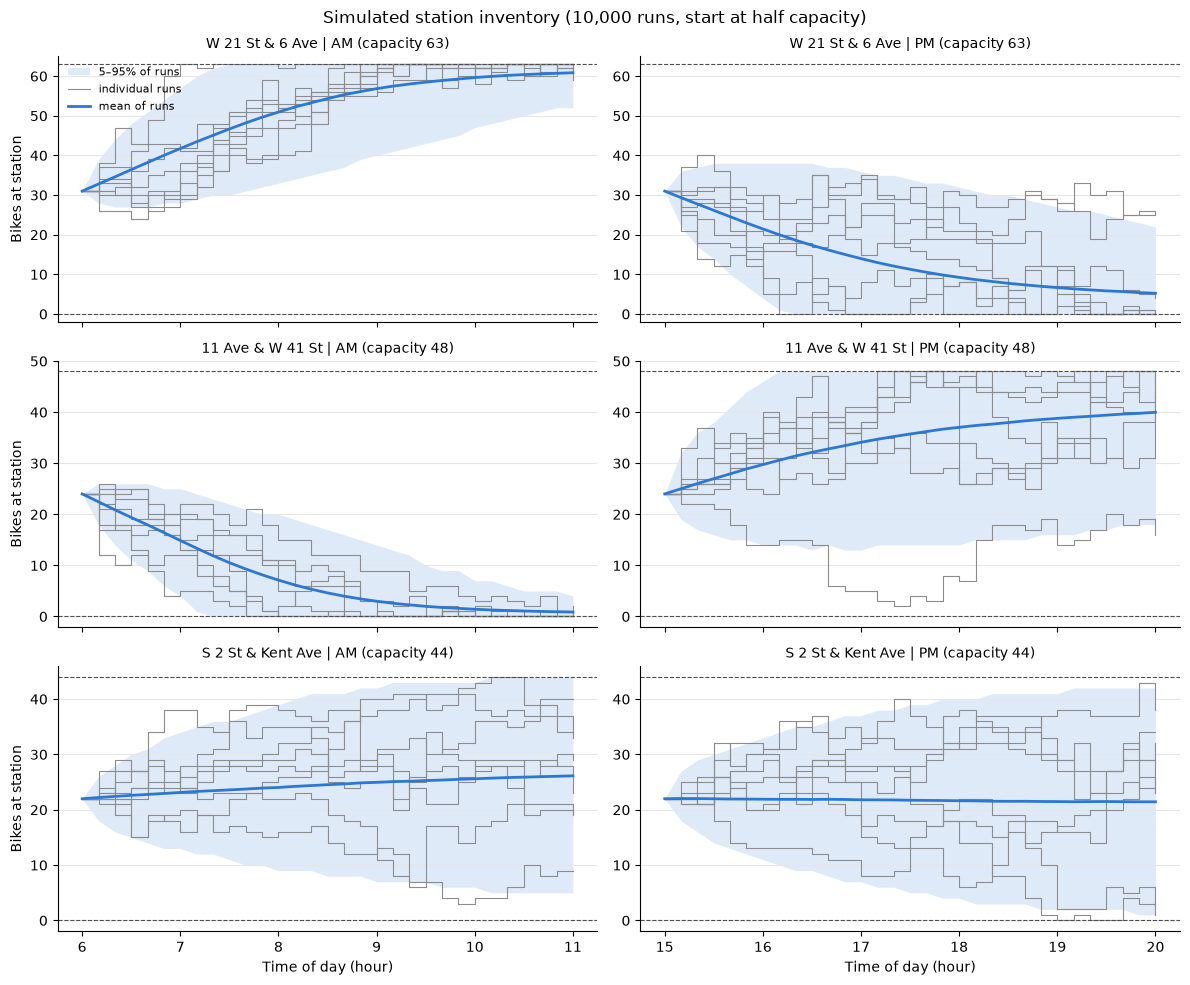

In [26]:
# Experiment 1: starting state for each station at capacity/2 (not looking at Combined Markov chain)
rng = np.random.default_rng(SEED)
def simulate_run(P, start_state, n_steps, rng):
    """One simulated path of the chain: returns states X_0, ..., X_n."""
    states = np.empty(n_steps + 1, dtype=int)
    states[0] = start_state
    for t in range(n_steps):
        states[t + 1] = rng.choice(len(P), p=P[states[t]])
    return states

def simulate_many(P, start_state, n_steps, n_runs, rng):
    return np.array([simulate_run(P, start_state, n_steps, rng) for _ in range(n_runs)])

sims = {}
for station, cap in zip(stations, station_capacities):
    sims[station] = {}
    for block in ["AM", "PM"]:
        sims[station][block] = simulate_many(MCs[station][block], cap //2, N_STEPS, N_RUNS, rng)

fig, axes = plt.subplots(len(stations), 2, figsize=(12,10), sharex='col')

for r, (station, cap) in enumerate(zip(stations, station_capacities)):
    for c, block in enumerate(["AM", "PM"]):
        ax = axes[r,c]
        paths = sims[station][block]
        hours = BLOCK_START[block] + np.arange(N_STEPS + 1) * STEP_MIN / 60

        lo, hi = np.percentile(paths, [5,95], axis = 0)
        ax.fill_between(hours, lo, hi, color="#2a78d6", alpha=0.15,
                        lw=0, label="5–95% of runs")

        for i, path in enumerate(paths[:N_SHOW]):
            ax.step(hours, path, where="post", color="0.55", lw=0.8,
                    label="individual runs" if i == 0 else None)
        ax.plot(hours, paths.mean(axis=0), color="#2a78d6", lw=2,
                label="mean of runs")

        ax.axhline(0, color="0.3", ls="--", lw=0.8)
        ax.axhline(cap, color="0.3", ls="--", lw=0.8)
        ax.set_ylim(-2, cap + 2)
        ax.set_title(f"{station} | {block} (capacity {cap})", fontsize=10)
        ax.grid(axis="y", color="0.9")
        ax.spines[["top", "right"]].set_visible(False)
        if c == 0:
            ax.set_ylabel("Bikes at station")
        if r == len(stations) - 1:
            ax.set_xlabel("Time of day (hour)")

axes[0, 0].legend(loc="upper left", fontsize=8, frameon=False)
fig.suptitle(f"Simulated station inventory ({N_RUNS:,} runs, start at half capacity)")
fig.tight_layout()
fig.savefig("images/simulation_runs.png", dpi=200, bbox_inches="tight")
plt.show()

## Calculating Probability that a Station Reaches Empty/Full 

In [27]:
rows = []
for station, cap in zip(stations, station_capacities):
    for block in ["AM", "PM"]:
        paths = sims[station][block][:, 1:]        # states after steps 1..30
        n = len(paths)

        hit_empty = (paths == 0).any(axis=1)       # per run: ever empty?
        hit_full  = (paths == cap).any(axis=1)     # per run: ever full?
        hit_any   = hit_empty | hit_full

        row = {"station": station, "block": block}
        for name, hits in [("P(ever empty)", hit_empty),
                           ("P(ever full)", hit_full),
                           ("P(ever unavailable)", hit_any)]:
            p = hits.mean()
            row[name] = p
            row[name + " ±"] = 1.96 * np.sqrt(p * (1 - p) / n)   # 95% CI half-width
        rows.append(row)

sim_results = pd.DataFrame(rows)
print(sim_results.round(3))

             station block  P(ever empty)  P(ever empty) ±  P(ever full)  \
0    W 21 St & 6 Ave    AM          0.000            0.000         0.902   
1    W 21 St & 6 Ave    PM          0.822            0.007         0.002   
2   11 Ave & W 41 St    AM          0.960            0.004         0.000   
3   11 Ave & W 41 St    PM          0.025            0.003         0.707   
4  S 2 St & Kent Ave    AM          0.056            0.005         0.172   
5  S 2 St & Kent Ave    PM          0.122            0.006         0.111   

   P(ever full) ±  P(ever unavailable)  P(ever unavailable) ±  
0           0.006                0.902                  0.006  
1           0.001                0.824                  0.007  
2           0.000                0.960                  0.004  
3           0.009                0.730                  0.009  
4           0.007                0.228                  0.008  
5           0.006                0.233                  0.008  


## Recommendation: Best Starting Inventory

In [28]:
def simulate_many_fast(P, start, n_steps, n_runs, rng):
    """Same as simulate_many, but advances all runs at once."""
    cdf = P.cumsum(axis=1)
    paths = np.empty((n_runs, n_steps + 1), dtype=int)
    paths[:, 0] = start
    for t in range(n_steps):
        u = rng.random(n_runs)[:, None]
        nxt = (u > cdf[paths[:, t]]).sum(axis=1)      # inverse-CDF draw from row X_t
        paths[:, t + 1] = np.minimum(nxt, len(P) - 1)
    return paths

SEARCH_RUNS = 2_000   # per starting level, for the search
rows = []
for station, cap in zip(stations, station_capacities):
    for block in ["AM", "PM"]:
        P = MCs[station][block]

        # 1. Search: simulate every interior starting level
        mean_min = {}
        for s in range(1, cap):
            after = simulate_many_fast(P, s, N_STEPS, SEARCH_RUNS, rng)[:, 1:]
            mean_min[s] = (((after == 0) | (after == cap)).sum(axis=1) * STEP_MIN).mean()
        best = min(mean_min, key=mean_min.get)

        # 2. Confirm with fresh runs: half capacity vs. best start
        for label, start in [("half", cap // 2), ("best", best)]:
            after = simulate_many_fast(P, start, N_STEPS, N_RUNS, rng)[:, 1:]
            unavail = (after == 0) | (after == cap)
            minutes = unavail.sum(axis=1) * STEP_MIN
            rows.append({"station": station, "block": block, "start": f"{label}: {start}",
                         "P(ever unavailable)": unavail.any(axis=1).mean(),
                         "E[min unavailable]": minutes.mean(),
                         "±": 1.96 * minutes.std(ddof=1) / np.sqrt(N_RUNS)})

rec_results = pd.DataFrame(rows)
print(rec_results.round(2).to_string(index=False))

          station block    start  P(ever unavailable)  E[min unavailable]    ±
  W 21 St & 6 Ave    AM half: 31                 0.90               82.71 1.01
  W 21 St & 6 Ave    AM  best: 3                 0.57               24.48 0.62
  W 21 St & 6 Ave    PM half: 31                 0.83               66.14 0.98
  W 21 St & 6 Ave    PM best: 56                 0.58               25.80 0.63
 11 Ave & W 41 St    AM half: 24                 0.96              106.34 1.01
 11 Ave & W 41 St    AM best: 47                 0.68               32.85 0.71
 11 Ave & W 41 St    PM half: 24                 0.73               50.67 0.96
 11 Ave & W 41 St    PM  best: 8                 0.61               28.90 0.68
S 2 St & Kent Ave    AM half: 22                 0.23                9.87 0.46
S 2 St & Kent Ave    AM best: 16                 0.22                8.99 0.43
S 2 St & Kent Ave    PM half: 22                 0.24                9.84 0.45
S 2 St & Kent Ave    PM best: 24                 0.2